# Módulo 9 — Análise Espectral
## Seção 9.2 — Função densidade espectral

**Objetivos de aprendizagem.** Definir formalmente a densidade espectral em tempo discreto; demonstrar propriedades de simetria, periodicidade, não negatividade e integral da variância; calcular espectros de ruído branco, MA(1) e AR(1); interpretar a localização da variância por frequência.

**Pré-requisitos.** Seções 4.1–4.2 (autocovariância), 8.3–8.6 (Euler, Fourier e DFT) e 9.1 (domínios temporal e frequencial). O conceito de estacionariedade fraca foi estabelecido no Módulo 1.

**Fonte principal conferida.** MORETTIN, P. A.; TOLOI, C. M. C. *Análise de séries temporais: modelos lineares univariados*, 3. ed., v. 1, capítulo 14, §14.2, pp. **357–362**: definição (14.2), Teorema 14.1 (p. 358), relação inversa (14.3), Exemplo 14.1 (p. 360), discussão de representações espectrais na §14.3 (p. 363 em diante). As demonstrações passo a passo abaixo são expansões pedagógicas dessas propriedades, não citações literais.

---

### 1. Motivação: como distribuir a variância entre frequências?

A autocovariância $\gamma(h)$ informa a dependência entre duas observações separadas por $h$ passos. Considere processos distintos com a mesma variância $\gamma(0)$: um ruído branco, uma série altamente persistente e uma série que alterna de sinal. Seus gráficos temporais e autocovariâncias são diferentes. A densidade espectral fornece outra maneira de caracterizar essas diferenças: a distribuição da variância pelos componentes de frequência.

**Intuição:** processos persistentes concentram mais variância em baixas frequências (oscilações lentas); processos com forte alternância podem concentrar variância em frequências próximas de $\pi$ radianos por amostra (oscilações rápidas). Isso não significa que uma única frequência determine completamente a série.

### 2. Hipóteses e definição formal

Considere um processo real $\{X_t\}_{t\in\mathbb Z}$, **fracamente estacionário**, com média constante $\mu$, variância finita e autocovariância

$$\gamma(h)=\operatorname{Cov}(X_t,X_{t+h}),\qquad h\in\mathbb Z.$$

**Hipótese suficiente adotada no livro, §14.2:**

$$\sum_{h=-\infty}^{\infty}|\gamma(h)|<\infty.$$

Essa condição de somabilidade absoluta garante a convergência uniforme da série de Fourier que define o espectro. **Não é condição necessária para toda representação espectral:** existem processos estacionários cujas medidas espectrais não têm densidade comum, ou cujas autocovariâncias não são absolutamente somáveis.

Sob essa hipótese, Morettin e Toloi definem, para $-\pi\leq\lambda\leq\pi$,

$$\boxed{f(\lambda)=\frac{1}{2\pi}\sum_{h=-\infty}^{\infty}\gamma(h)e^{-i\lambda h}.}\tag{9.1}$$

Aqui, $f(\lambda)$ é a densidade espectral em função da **frequência angular digital** $\lambda$ (rad/amostra). A normalização $1/(2\pi)$ segue a equação (14.2) do livro. Alguns softwares exibem densidade por ciclo/unidade de tempo, usando outra escala — comparar resultados exige converter as unidades.

### 3. Propriedade 1 — Simetria e realidade

Como a covariância é simétrica,

$$\gamma(-h)=\operatorname{Cov}(X_t,X_{t-h})=\gamma(h).$$

Separando a soma em $h=0$, lags positivos e negativos:

$$\begin{aligned}
2\pi f(\lambda)&=\gamma(0)+\sum_{h=1}^{\infty}\gamma(h)e^{-i\lambda h}+\sum_{h=1}^{\infty}\gamma(-h)e^{i\lambda h}\\
&=\gamma(0)+\sum_{h=1}^{\infty}\gamma(h)\left[e^{-i\lambda h}+e^{i\lambda h}\right].
\end{aligned}$$

Pela identidade de Euler, $e^{-iz}+e^{iz}=2\cos z$. Logo,

$$\boxed{f(\lambda)=\frac{1}{2\pi}\left[\gamma(0)+2\sum_{h=1}^{\infty}\gamma(h)\cos(\lambda h)\right].}\tag{9.2}$$

Essa expressão é **real**. E como $\cos(-\lambda h)=\cos(\lambda h)$, segue que $f(-\lambda)=f(\lambda)$. Isso permite analisar apenas $\lambda\in[0,\pi]$ para séries reais, com cuidado para não duplicar indevidamente a variância nas bordas.

### 4. Propriedade 2 — Periodicidade

Para $h\in\mathbb Z$, temos

$$e^{-i(\lambda+2\pi)h}=e^{-i\lambda h}e^{-i2\pi h}=e^{-i\lambda h}.$$

Portanto,

$$\boxed{f(\lambda+2\pi)=f(\lambda).}$$

A periodicidade do espectro de tempo discreto decorre da própria amostragem e das frequências indistinguíveis módulo $2\pi$; não significa que o processo $X_t$ seja periódico no tempo.

### 5. Propriedade 3 — Inversão: recuperando a autocovariância

Para qualquer $k\in\mathbb Z$, integre (9.1) contra $e^{i\lambda k}$:

$$\int_{-\pi}^{\pi}e^{i\lambda k}f(\lambda)\,d\lambda=\frac{1}{2\pi}\sum_{h=-\infty}^{\infty}\gamma(h)\int_{-\pi}^{\pi}e^{i\lambda(k-h)}\,d\lambda.$$

A troca entre soma e integral é justificada aqui pela somabilidade absoluta. Por ortogonalidade das exponenciais complexas,

$$\frac{1}{2\pi}\int_{-\pi}^{\pi}e^{i\lambda(k-h)}d\lambda=\begin{cases}1,&h=k,\\0,&h\neq k.\end{cases}$$

Assim, todos os termos desaparecem, exceto $h=k$:

$$\boxed{\gamma(k)=\int_{-\pi}^{\pi}e^{i\lambda k}f(\lambda)\,d\lambda.}\tag{9.3}$$

Esta é a relação inversa (14.3) do livro. **Interpretação:** a autocovariância e o espectro contêm a mesma informação de segunda ordem quando as hipóteses são satisfeitas.

### 6. Propriedade 4 — A variância é a área do espectro

Faça $k=0$ em (9.3):

$$\gamma(0)=\int_{-\pi}^{\pi}f(\lambda)\,d\lambda.$$

Como $\gamma(0)=\operatorname{Var}(X_t)$, concluímos:

$$\boxed{\operatorname{Var}(X_t)=\int_{-\pi}^{\pi}f(\lambda)\,d\lambda.}\tag{9.4}$$

**Exemplo numérico.** Se $f(\lambda)=2/\pi$ para todo $\lambda\in[-\pi,\pi]$, então $\operatorname{Var}(X_t)=(2/\pi)\cdot(2\pi)=4$. A constante correta para ruído branco com variância $4$ é $4/(2\pi)=2/\pi$.

> **Atenção às unidades:** para uma densidade bilateral em rad/amostra, a área em $[-\pi,\pi]$ é a variância. Se adotarmos densidade unilateral em $[0,\pi]$, seu valor deve ser dobrado no interior do intervalo para preservar essa área, respeitando as convenções nas extremidades.

### 7. Propriedade 5 — Não negatividade

O Teorema 14.1 de Morettin e Toloi afirma que $f(\lambda)\geq0$. A ideia matemática vem do fato de que a matriz de autocovariâncias é **não negativa definida**.

Considere o polinômio complexo $S_N(\lambda)=\sum_{t=0}^{N-1}(X_t-\mu)e^{-i\lambda t}$. Como $|S_N|^2\geq0$ em qualquer realização,

$$\begin{aligned}
\frac{1}{2\pi N}\operatorname E|S_N(\lambda)|^2
&=\frac{1}{2\pi N}\sum_{t,s=0}^{N-1}\gamma(t-s)e^{-i\lambda(t-s)}\\
&=\frac1{2\pi}\sum_{|h|<N}\left(1-\frac{|h|}{N}\right)\gamma(h)e^{-i\lambda h}\geq0.
\end{aligned}$$

A última soma é uma média de Fejér das séries de Fourier. Pela somabilidade absoluta de $\gamma(h)$, ela converge a $f(\lambda)$ quando $N\to\infty$. Como cada aproximação é não negativa, seu limite também o é. Esse argumento justifica a propriedade sem precisar supor normalidade gaussiana.

### 8. Exemplo teórico 1 — Ruído branco

Se $\varepsilon_t$ é ruído branco de média zero e variância $\sigma^2$, então

$$\gamma(0)=\sigma^2,\qquad \gamma(h)=0\quad(h\neq0).$$

Substituindo em (9.1):

$$\boxed{f_\varepsilon(\lambda)=\frac{\sigma^2}{2\pi}.}$$

Logo, **o espectro do ruído branco é plano**, pois sua autocovariância desaparece em todos os lags não nulos. Não devemos interpretar um periodograma amostral com picos isolados como prova de que o processo não é ruído branco: a estimativa de uma única amostra flutua aleatoriamente.

### 9. Exemplo teórico 2 — MA(1)

Considere $X_t=\varepsilon_t+\theta\varepsilon_{t-1}$, com ruído branco de variância $\sigma^2$. Calculemos suas autocovariâncias:

$$\gamma(0)=\operatorname{Var}(\varepsilon_t+\theta\varepsilon_{t-1})=\sigma^2(1+\theta^2).$$

$$\gamma(1)=\operatorname{Cov}(\varepsilon_t+\theta\varepsilon_{t-1},\varepsilon_{t+1}+\theta\varepsilon_t)=\theta\sigma^2.$$

Para $|h|>1$, não há choques em comum: $\gamma(h)=0$. Substituindo em (9.2):

$$\begin{aligned}
f_X(\lambda)&=\frac{\sigma^2}{2\pi}\left(1+\theta^2+2\theta\cos\lambda\right)\\
&=\boxed{\frac{\sigma^2}{2\pi}|1+\theta e^{-i\lambda}|^2.}
\end{aligned}$$

**Interpretação:** para $\theta>0$, $f_X(0)=\sigma^2(1+\theta)^2/(2\pi)$ é maior que $f_X(\pi)=\sigma^2(1-\theta)^2/(2\pi)$: predominam frequências baixas. Para $\theta<0$, ocorre o contrário.

**Verificação da área:**

$$\int_{-\pi}^{\pi}f_X(\lambda)d\lambda=\frac{\sigma^2}{2\pi}\left[2\pi(1+\theta^2)+2\theta\int_{-\pi}^{\pi}\cos\lambda\,d\lambda\right]=\sigma^2(1+\theta^2),$$

igual à variância encontrada diretamente.

### 10. Exemplo teórico 3 — AR(1)

Considere $X_t=\phi X_{t-1}+\varepsilon_t$, com $|\phi|<1$ e inovações de variância $\sigma^2$. Sob a representação causal estacionária,

$$X_t=\sum_{j=0}^{\infty}\phi^j\varepsilon_{t-j}.$$

A soma geométrica das potências complexas fornece a resposta de frequência do filtro:

$$H(\lambda)=\sum_{j=0}^{\infty}\phi^j e^{-i\lambda j}=\frac{1}{1-\phi e^{-i\lambda}}.$$

Como a densidade de entrada é $\sigma^2/(2\pi)$, a densidade de saída do filtro linear é $|H(\lambda)|^2\sigma^2/(2\pi)$; assim,

$$\boxed{f_X(\lambda)=\frac{\sigma^2}{2\pi\left(1+\phi^2-2\phi\cos\lambda\right)}.}$$

**Justificativa adicional por autocovariâncias.** Para $|\phi|<1$, $\gamma(h)=\sigma^2\phi^{|h|}/(1-\phi^2)$. Substituindo-a em (9.2) e somando a série geométrica obtém-se a mesma expressão, conectando diretamente ao capítulo 5 do livro.

**Exemplo numérico:** com $\phi=0{,}8$ e $\sigma^2=1$,

$$f_X(0)=\frac{1}{2\pi(0{,}2)^2}\approx3{,}979,\qquad f_X(\pi)=\frac{1}{2\pi(1{,}8)^2}\approx0{,}0491.$$

A razão é $(1{,}8/0{,}2)^2=81$. Portanto, baixa frequência tem densidade **81 vezes** maior que alta frequência, ainda que a variância total permaneça finita.

### 11. Laboratório Python — três espectros teóricos

A biblioteca `numpy` implementa operações vetoriais, e `matplotlib` constrói os gráficos. Aqui usaremos **fórmulas teóricas**, não uma estimação por FFT.

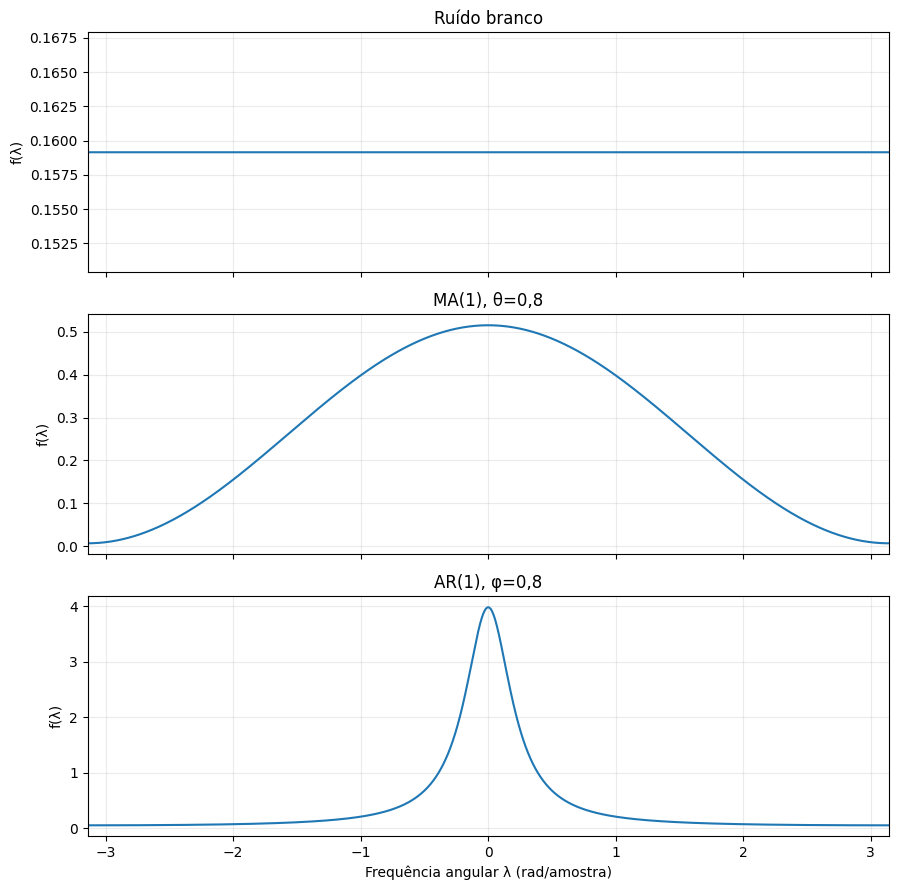

Áreas aproximadas:
RB 1.0000000000000002
MA(1) 1.6400000000000001
AR(1) 2.777777777777777


In [1]:
import numpy as np
import matplotlib.pyplot as plt
lam = np.linspace(-np.pi, np.pi, 2001)
sigma2 = 1.0
theta = 0.8
phi = 0.8
f_wn = np.full(lam.shape, sigma2/(2*np.pi))
f_ma = sigma2/(2*np.pi)*(1+theta**2+2*theta*np.cos(lam))
f_ar = sigma2/(2*np.pi)/(1+phi**2-2*phi*np.cos(lam))
fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True)
for ax, f, name in zip(axes,[f_wn,f_ma,f_ar],['Ruído branco','MA(1), θ=0,8','AR(1), φ=0,8']):
    ax.plot(lam, f)
    ax.set(ylabel='f(λ)', title=name)
    ax.grid(alpha=.25)
axes[-1].set(xlabel='Frequência angular λ (rad/amostra)', xlim=(-np.pi,np.pi))
plt.tight_layout(); plt.show()
print('Áreas aproximadas:')
for name,f in [('RB',f_wn),('MA(1)',f_ma),('AR(1)',f_ar)]:
    print(name, np.trapezoid(f,lam))
assert abs(np.trapezoid(f_wn,lam)-1) < 1e-4
assert abs(np.trapezoid(f_ma,lam)-(1+theta**2)) < 2e-4
assert abs(np.trapezoid(f_ar,lam)-1/(1-phi**2)) < 5e-4

**Interpretação esperada:** o ruído branco possui espectro horizontal; o MA(1) com $\theta>0$ favorece baixas frequências; o AR(1) persistente apresenta pico ainda mais acentuado próximo de zero. As integrais numéricas recuperam aproximadamente as variâncias $1$, $1+0{,}8^2=1{,}64$ e $1/(1-0{,}8^2)\approx2{,}7778$.

### 12. Laboratório Python — autocovariância e espectro são equivalentes

Vamos aproximar diretamente a soma (9.2) para um AR(1) utilizando somente 40 lags e compará-la à fórmula fechada.

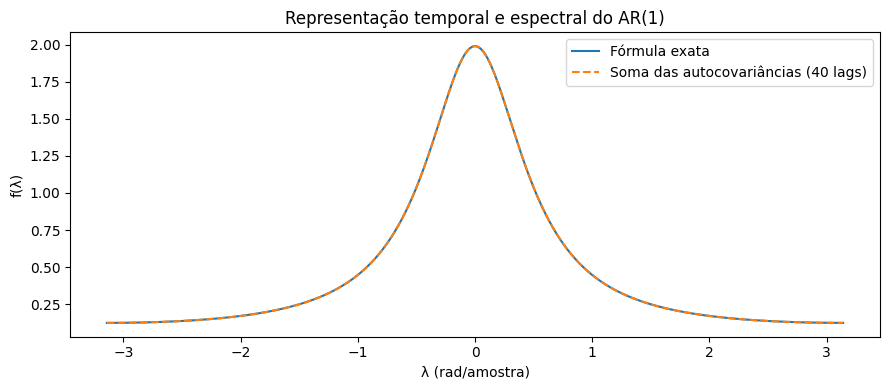

Erro máximo: 1.9945340934413025e-09


In [2]:
phi = 0.6
sig2 = 2.0
H = 40
gamma = np.array([sig2/(1-phi**2)*phi**h for h in range(H+1)])
f_soma = (gamma[0] + 2*np.sum(gamma[1:,None]*np.cos(np.arange(1,H+1)[:,None]*lam[None,:]),axis=0))/(2*np.pi)
f_exata = sig2/(2*np.pi)/(1+phi**2-2*phi*np.cos(lam))
fig, ax = plt.subplots(figsize=(9,4))
ax.plot(lam, f_exata, label='Fórmula exata')
ax.plot(lam, f_soma, '--', label='Soma das autocovariâncias (40 lags)')
ax.set(xlabel='λ (rad/amostra)',ylabel='f(λ)',title='Representação temporal e espectral do AR(1)')
ax.legend(); plt.tight_layout(); plt.show()
print('Erro máximo:', np.max(np.abs(f_soma-f_exata)))
assert np.max(np.abs(f_soma-f_exata)) < 1e-7

A aproximação funciona porque $|\phi|<1$ torna as autocovariâncias absolutamente somáveis. Para um AR(1) próximo da raiz unitária, serão necessários mais lags para aproximar adequadamente um pico espectral muito estreito.

### 13. Cuidados metodológicos

1. **Estacionariedade é crucial:** uma caminhada aleatória não possui variância constante e a fórmula ordinária (9.1) não se aplica diretamente aos níveis como se fossem estacionários.
2. **Densidade não é periodograma:** o espectro aqui é função teórica da autocovariância; estimadores amostrais serão discutidos nas seções seguintes.
3. **Não negatividade não significa independência:** processos dependentes podem compartilhar a mesma variância, com densidades diferentes.
4. **A somabilidade absoluta é suficiente, não universal:** processos de memória longa podem exigir tratamento espectral mais cuidadoso.
5. **Espectros de linhas:** processos estacionários podem possuir componentes espectrais discretas; a densidade não representa necessariamente toda a medida espectral.
6. **Convenção:** nosso $\lambda$ está em rad/amostra e $f$ é bilateral. Bibliotecas podem usar ciclos/unidade de tempo e normalizações diferentes.

### 14. Exercícios orientados

**Exercício 1.** Demonstre a identidade (9.2) explicitamente agrupando os termos de lags $h$ e $-h$.

**Exercício 2.** Para $X_t=\varepsilon_t-0{,}5\varepsilon_{t-1}$, obtenha $\gamma(0)$, $\gamma(1)$, $f(0)$ e $f(\pi)$ sem software. Interprete a diferença para $\theta>0$.

**Exercício 3.** Para $\phi=-0{,}7$ no AR(1), compare $f(0)$ com $f(\pi)$. A predominância estará em frequências altas ou baixas?

**Exercício 4.** Mostre que, para um processo real fracamente estacionário sob a hipótese de somabilidade absoluta, $\int_{-\pi}^{\pi}f(\lambda)\,d\lambda=\gamma(0)$.

**Exercício 5.** Em Python, modifique `theta` ou `phi` e compare graficamente modelos com a mesma variância marginal. Discuta por que a variância total não determina a forma do espectro.

**Exercício 6 (desafio conceitual).** Uma série apresenta forte crescimento ao longo do tempo. É legítimo usar a fórmula (9.1) diretamente sobre ela? Discuta as hipóteses e uma estratégia de análise apropriada.

**Pseudocódigo para o Exercício 5:** escolher dois parâmetros → calcular variâncias teóricas → escolher as variâncias das inovações de modo que a variância marginal seja igual → construir $f(\lambda)$ → integrar numericamente → comparar gráficos.

### 15. Síntese e próximas conexões

Aprendemos que a densidade espectral é a transformada de Fourier da autocovariância, que sua área total é a variância do processo e que modelos com diferentes estruturas de dependência distribuem essa variância de forma diferente entre frequências. A Seção **9.3** aprofundará a relação entre autocovariância e espectro; a **9.4** discutirá como estimar o espectro a partir de uma amostra com o periodograma.